In [2]:
import torch
from torch import nn, optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [ ]:
tf = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
    transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5])
])

train_dl = DataLoader(
    datasets.ImageFolder("data/Training", tf),
    batch_size=32,
    shuffle=True,
    num_workers=4,
    pin_memory=False
)

test_dl = DataLoader(
    datasets.ImageFolder("data/Testing", tf),
    batch_size=32,
    shuffle=False,
    num_workers=4,
    pin_memory=False
)

In [7]:
model = nn.Sequential(
    nn.Conv2d(3, 32, 3, 1, 1), nn.ReLU(), nn.MaxPool2d(2),
    nn.Conv2d(32, 64, 3, 1, 1), nn.ReLU(), nn.MaxPool2d(2),
    nn.Conv2d(64, 128, 3, 1, 1), nn.ReLU(), nn.MaxPool2d(2),
    nn.Flatten(),
    nn.Linear(128 * 16 * 16, 256), nn.ReLU(), nn.Dropout(0.5),
    nn.Linear(256, 4)
).to(device)

In [8]:
opt = optim.AdamW(model.parameters(), 1e-4)
loss_fn = nn.CrossEntropyLoss()

In [ ]:
model.train()

for epoch in range(25):
    running_loss = 0

    for x, y in train_dl:
        opt.zero_grad()

        loss = loss_fn(model(x.to(device)), y.to(device))
        loss.backward()

        running_loss += loss

        opt.step()

    print(f"Epoch {epoch + 1} Loss was {running_loss}")

In [ ]:
model.eval()

test_loss, correct = 0.0, 0

with torch.no_grad():
    for x, y in test_dl:
        x, y = x.to(device), y.to(device)

        logits = model(x)
        test_loss += loss_fn(logits, y).item() * y.size(0)

        pred = logits.argmax(dim=1)
        correct += (pred == y).sum().item()

test_loss /= len(test_dl.dataset)
accuracy = 100 * correct / len(test_dl.dataset)

print("Test Loss:", test_loss)
print("Test Accuracy:", accuracy)

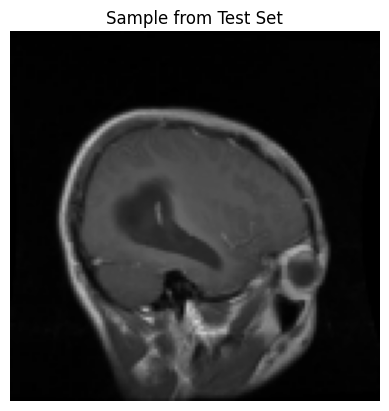

Predicted: glioma
Ground Truth: glioma


In [16]:
import random

import matplotlib.pyplot as plt
from torchvision.transforms.functional import to_pil_image

model.eval()

idx = random.randrange(len(test_dl.dataset))
img, label = test_dl.dataset[idx]

unnorm = img * 0.5 + 0.5
plt.imshow(to_pil_image(unnorm))
plt.axis("off")
plt.title("Sample from Test Set")
plt.show()

with torch.no_grad():
    logits = model(img.unsqueeze(0).to(device))
    pred = logits.argmax(dim=1).item()

class_names = test_dl.dataset.classes
print(f"Predicted: {class_names[pred]}")
print(f"Ground Truth: {class_names[label]}")

In [17]:
torch.save(model.state_dict(), "brain_tumor_model.pth")

In [19]:
import joblib
# Save
joblib.dump(model, "brain_tumor_model.pkl")

['brain_tumor_model.pkl']